# Globale Störung der Zivilen Luftfahrt durch Iran vs USA

<img src="https://www.fr.de/assets/images/41/3/41003217-alle-fluege-betroffen-auf-der-website-flightaware-ist-zu-sehen-dass-sich-aktuell-kaum-ein-flugzeug-ueber-griechenland-befindet-1mzdDDBgRAef.jpg" width=700>

# Introduction

Geopolitical tensions and airspace restrictions can disrupt civil aviation through flight cancellations, rerouting, airport interruptions, and additional operating costs. This project explores these patterns in an aviation-disruption dataset framed around Iran–USA tensions.

The analysis combines six datasets covering airline financial losses, airport disruptions, airspace closures, conflict events, flight cancellations, and flight reroutes. Using Python, Pandas, Seaborn, Matplotlib, and Plotly, it examines regional differences, operational trends, and relationships between disruptions and estimated financial losses.

The project also applies feature engineering and compares Linear Regression, Random Forest, and XGBoost models to predict estimated airline financial losses. Feature importance and SHAP are used to interpret the models.

Project objectives:
- Explore the scale and geographic distribution of aviation disruptions.
- Visualize cancellations, reroutes, delays, and estimated financial impacts.
- Identify patterns in airline and airport operational risk.
- Compare regression models and examine the factors associated with estimated losses.

Data note: The notebook does not currently document the original data sources or establish whether the records are observed, simulated, or estimated. Results should therefore be interpreted as findings within the supplied datasets, not independently verified real-world impacts.

# Import Libraries

In [1]:
%pip install -U kaleido

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install -U plotly kaleido

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
#!pip install shap

In [4]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from sklearn.model_selection import (
    train_test_split,
    cross_val_score
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import shap
sns.set_style('whitegrid')

# Load Dataset

In [5]:
airline = pd.read_csv('airline_losses.csv')
airport = pd.read_csv('airport_disruptions.csv')
airspace = pd.read_csv('airspace_closures.csv')
conflict = pd.read_csv('conflict_events.csv')
cancellations = pd.read_csv('flight_cancellations.csv')
reroutes = pd.read_csv('flight_reroutes.csv')

# EDA

In [6]:
airline.head()

,airline,country,airline_type,estimated_loss_usd,cancellations_count,reroutes_count,revenue_loss_pct,region
0,Air Arabia,UAE,Low Cost,1.085190e+09,125,111,26.2,Middle East
1,Kuwait Airways,Kuwait,Flag Carrier,1.075730e+09,133,87,40.6,Middle East
2,Etihad Airways,UAE,Flag Carrier,8.843600e+08,74,104,19.2,Middle East
3,flynas,Saudi Arabia,Low Cost,6.274000e+08,225,70,46.0,Middle East
4,Emirates SkyCargo,UAE,Cargo,6.268600e+08,253,101,35.1,Middle East


In [7]:
airline.tail()

,airline,country,airline_type,estimated_loss_usd,cancellations_count,reroutes_count,revenue_loss_pct,region
65,TAP Air Portugal,Portugal,Flag Carrier,25550000.0,18,39,6.9,Europe
66,Ryanair,Ireland,Low Cost,14640000.0,26,15,11.9,Europe
67,Qantas,Australia,Flag Carrier,11520000.0,29,15,9.9,Asia Pacific
68,Wizz Air,Hungary,Low Cost,10330000.0,32,22,9.6,Europe
69,Garuda Indonesia,Indonesia,Flag Carrier,8550000.0,15,12,5.0,Asia Pacific


| Spalte              | Bedeutung                               |
| ------------------- | --------------------------------------- |
| airline             | Name der Fluggesellschaft               |
| country             | Land der Airline                        |
| airline_type        | Typ der Airline                         |
| estimated_loss_usd  | Geschätzter finanzieller Verlust in USD |
| cancellations_count | Anzahl ausgefallener Flüge              |
| reroutes_count      | Anzahl umgeleiteter Flüge               |
| revenue_loss_pct    | Prozentualer Umsatzverlust              |
| region              | Weltregion der Airline                  |


In [8]:
airline.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70 entries, 0 to 69
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   airline              70 non-null     object 
 1   country              70 non-null     object 
 2   airline_type         70 non-null     object 
 3   estimated_loss_usd   70 non-null     float64
 4   cancellations_count  70 non-null     int64  
 5   reroutes_count       70 non-null     int64  
 6   revenue_loss_pct     70 non-null     float64
 7   region               70 non-null     object 
dtypes: float64(2), int64(2), object(4)
memory usage: 4.5+ KB


In [9]:
airline.shape

(70, 8)

In [10]:
airline.isnull().sum()

airline                0
country                0
airline_type           0
estimated_loss_usd     0
cancellations_count    0
reroutes_count         0
revenue_loss_pct       0
region                 0
dtype: int64

In [11]:
airline.columns

Index(['airline', 'country', 'airline_type', 'estimated_loss_usd',
       'cancellations_count', 'reroutes_count', 'revenue_loss_pct', 'region'],
      dtype='object')

In [12]:
airline.describe()

,estimated_loss_usd,cancellations_count,reroutes_count,revenue_loss_pct
count,7.000000e+01,70.000000,70.000000,70.000000
mean,1.525400e+08,59.785714,41.857143,13.754286
std,2.360989e+08,62.315674,30.894062,11.973699
min,8.550000e+06,8.000000,9.000000,2.800000
25%,4.487500e+07,21.000000,19.500000,6.700000
50%,6.279500e+07,36.000000,32.500000,8.950000
75%,8.670750e+07,61.500000,58.250000,16.500000
max,1.085190e+09,253.000000,136.000000,51.600000


In [13]:
airline.corr(numeric_only=True)

,estimated_loss_usd,cancellations_count,reroutes_count,revenue_loss_pct
estimated_loss_usd,1.000000,0.626398,0.707418,0.722462
cancellations_count,0.626398,1.000000,0.728640,0.825075
reroutes_count,0.707418,0.728640,1.000000,0.667039
revenue_loss_pct,0.722462,0.825075,0.667039,1.000000


In [14]:
airline.duplicated().sum()

np.int64(0)

In [15]:
airline['estimated_loss_usd'].max()

1085190000.0

In [16]:
airport.head()

,airport_name,iata_code,country,region,disruption_type,severity_level,flights_affected,duration_hours,date
0,Kuwait International Airport,KWI,Kuwait,Middle East,Partial Closure,Severe,133,55.7,2026-02-27
1,Muscat International Airport,MCT,Oman,Middle East,Security Lockdown,High,83,24.8,2026-02-27
2,Helsinki-Vantaa Airport,HEL,Finland,Europe,Partial Closure,Moderate,37,34.0,2026-02-28
3,Dubai International Airport,DXB,UAE,Middle East,Staff Evacuation,High,239,3.3,2026-02-28
4,Kuwait International Airport,KWI,Kuwait,Middle East,Departure Delays,High,84,48.8,2026-02-28


In [17]:
airport.tail()

,airport_name,iata_code,country,region,disruption_type,severity_level,flights_affected,duration_hours,date
212,Santiago Arturo Merino Benítez Airport,SCL,Chile,Latin America,Flight Cancellations,Low,207,32.2,2026-05-02
213,Abu Dhabi International Airport,AUH,UAE,Middle East,Arrival Diversions,Critical,150,61.0,2026-05-02
214,Sheremetyevo International Airport,SVO,Russia,Europe,Full Closure,Low,300,59.2,2026-05-02
215,Damascus International Airport,DAM,Syria,Middle East,Flight Cancellations,Critical,150,56.0,2026-05-03
216,Mehrabad International Airport,THR,Iran,Middle East,ATC Flow Restriction,High,35,3.9,2026-05-03


In [18]:
airport.shape

(217, 9)

In [19]:
airport.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   airport_name      217 non-null    object 
 1   iata_code         217 non-null    object 
 2   country           217 non-null    object 
 3   region            217 non-null    object 
 4   disruption_type   217 non-null    object 
 5   severity_level    217 non-null    object 
 6   flights_affected  217 non-null    int64  
 7   duration_hours    217 non-null    float64
 8   date              217 non-null    object 
dtypes: float64(1), int64(1), object(7)
memory usage: 15.4+ KB


In [20]:
airport.isnull().sum()

airport_name        0
iata_code           0
country             0
region              0
disruption_type     0
severity_level      0
flights_affected    0
duration_hours      0
date                0
dtype: int64

In [21]:
airport.duplicated().sum()

np.int64(0)

In [22]:
airport.describe()

,flights_affected,duration_hours
count,217.000000,217.000000
mean,156.884793,37.746544
std,80.686181,20.085376
min,6.000000,2.000000
25%,87.000000,21.900000
50%,150.000000,37.700000
75%,221.000000,55.800000
max,300.000000,71.700000


In [23]:
airspace.head()

,country,region,closure_start_date,closure_end_date,duration_hours,airspace_zone,reason,flights_affected
0,Yemen,Middle East,2026-02-28 01:03,2026-03-07 01:03,168,Full Airspace,Drone/UAV threat — altitude restriction,349
1,Afghanistan,Central Asia,2026-02-28 14:19,2026-03-03 14:19,72,UIR,Temporary restriction — missile trajectory zone,151
2,Saudi Arabia,Middle East,2026-03-01 00:33,2026-03-03 00:33,48,Full Airspace,Active combat zone — civilian restriction,735
3,Lebanon,Middle East,2026-03-01 00:37,2026-03-11 00:37,240,ADIZ,Precautionary closure — conflict proximity,435
4,Turkmenistan,Central Asia,2026-03-01 02:39,2026-03-03 02:39,48,UIR,Temporary restriction — missile trajectory zone,142


In [24]:
airspace.tail()

,country,region,closure_start_date,closure_end_date,duration_hours,airspace_zone,reason,flights_affected
50,UAE,Middle East,2026-04-25 05:52,2026-04-25 11:52,6,UIR,ATC flow management due corridor congestion,18
51,Iraq,Middle East,2026-04-28 10:46,2026-04-28 22:46,12,Partial Restriction,ATC flow management due corridor congestion,114
52,Qatar,Middle East,2026-05-01 08:57,2026-05-01 20:57,12,Partial Restriction,Temporary safety closure — route deconfliction,21
53,Iran,Middle East,2026-05-02 10:55,2026-05-03 22:55,36,UIR,GPS interference advisory — altitude/time rest...,215
54,Iran,Middle East,2026-05-03 14:52,2026-05-04 08:52,18,Partial Restriction,Temporary safety closure — route deconfliction,121


In [25]:
airspace.shape

(55, 8)

In [26]:
airspace.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55 entries, 0 to 54
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   country             55 non-null     object
 1   region              55 non-null     object
 2   closure_start_date  55 non-null     object
 3   closure_end_date    55 non-null     object
 4   duration_hours      55 non-null     int64 
 5   airspace_zone       55 non-null     object
 6   reason              55 non-null     object
 7   flights_affected    55 non-null     int64 
dtypes: int64(2), object(6)
memory usage: 3.6+ KB


In [27]:
airspace.isnull().sum()

country               0
region                0
closure_start_date    0
closure_end_date      0
duration_hours        0
airspace_zone         0
reason                0
flights_affected      0
dtype: int64

In [28]:
airspace.describe()

,duration_hours,flights_affected
count,55.000000,55.000000
mean,82.800000,323.200000
std,89.817593,250.778152
min,6.000000,18.000000
25%,24.000000,114.000000
50%,48.000000,215.000000
75%,108.000000,552.000000
max,336.000000,798.000000


In [29]:
conflict.head()

,date,event_type,event_description,location,severity,aviation_impact
0,2025-12-15,Political,Widespread anti-government protests erupt acro...,"Tehran, Iran",High,Minimal — early warning signs only
1,2026-01-10,Diplomatic,UN Security Council emergency session on Iran ...,"New York, USA",Medium,Airlines begin monitoring situation
2,2026-01-25,Military,US deploys additional carrier strike group to ...,Persian Gulf,High,Airlines issue internal risk advisories
3,2026-02-05,Diplomatic,Geneva nuclear talks begin — mediated by Oman ...,"Geneva, Switzerland",Medium,Brief de-escalation — normal flight ops
4,2026-02-14,Political,Iran announces uranium enrichment to 90% — tal...,"Tehran, Iran",Very High,Airlines begin contingency route planning


In [30]:
conflict.tail()

,date,event_type,event_description,location,severity,aviation_impact
57,2026-04-30,Economic,Monthly aviation recovery index reaches 97% of...,Global,Low,Airlines cautiously optimistic for summer seas...
58,2026-05-01,Regulatory,ICAO publishes final conflict-zone NOTAM frame...,"Montreal, Canada",Low,Standardized amber-watch protocol replaces pat...
59,2026-05-02,Security,Isolated GPS spoofing incident near Qatar FIR ...,Qatar FIR,Low,Short-lived restriction resolved by afternoon ...
60,2026-05-03,Diplomatic,Joint Iran-US technical committee meets in Gen...,"Geneva, Switzerland",Low,Structural progress toward long-term stability...
61,2026-05-04,Situation,Current status as of 4 May 2026: Aviation reco...,Global,Low,Near-normal operations globally; minor war-ris...


In [31]:
conflict.shape

(62, 6)

In [32]:
conflict.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   date               62 non-null     object
 1   event_type         62 non-null     object
 2   event_description  62 non-null     object
 3   location           62 non-null     object
 4   severity           62 non-null     object
 5   aviation_impact    62 non-null     object
dtypes: object(6)
memory usage: 3.0+ KB


In [33]:
conflict.describe()

,date,event_type,event_description,location,severity,aviation_impact
count,62,62,62,62,62,62
unique,62,10,62,32,5,62
top,2025-12-15,Diplomatic,Widespread anti-government protests erupt acro...,"Montreal, Canada",Medium,Minimal — early warning signs only
freq,1,14,1,6,24,1


In [34]:
conflict.isnull().sum()

date                 0
event_type           0
event_description    0
location             0
severity             0
aviation_impact      0
dtype: int64

In [35]:
conflict.duplicated().sum()

np.int64(0)

In [36]:
cancellations.head()

,date,airline,flight_number,origin,destination,origin_country,destination_country,aircraft_type,passengers_affected,reason
0,2026-02-27,Vietnam Airlines,VI7914,Karachi,Istanbul,Pakistan,Turkey,Airbus A340-600,326,Airspace closure — NOTAM
1,2026-02-27,Iberia,IB2542,London,Nairobi,UK,Kenya,Boeing 737-800,124,Crew safety — company policy
2,2026-02-27,Air Canada,AI2618,Madrid,Bogotá,Spain,Colombia,Airbus A330-300,371,Crew duty-time exceedance after long reroutes
3,2026-02-27,Azul Brazilian Airlines,AZ6422,Lahore,Doha,Pakistan,Qatar,Airbus A321neo,145,Crew duty-time exceedance after long reroutes
4,2026-02-27,TAP Air Portugal,TA2694,London,Kuwait City,UK,Kuwait,Boeing 777-300ER,268,Security risk — conflict zone


In [37]:
cancellations.tail()

,date,airline,flight_number,origin,destination,origin_country,destination_country,aircraft_type,passengers_affected,reason
1395,2026-05-03,Kuwait Airways,KU7750,Seoul,Dubai,South Korea,UAE,Boeing 737 MAX 8,402,Airspace closure — NOTAM
1396,2026-05-03,Emirates SkyCargo,EM1394,London,Beijing,UK,China,Airbus A321neo,277,Airport closure — military activity
1397,2026-05-03,Vietnam Airlines,VI325,Bogotá,Madrid,Colombia,Spain,Boeing 737-800,211,Diplomatic advisory — do not fly
1398,2026-05-03,Air New Zealand,AI7398,Dubai,Warsaw,UAE,Poland,Boeing 737 MAX 8,406,Diplomatic advisory — do not fly
1399,2026-05-03,UPS Airlines,UP5967,Dubai,São Paulo,UAE,Brazil,Airbus A350-900,123,Crew safety — company policy


In [38]:
cancellations.shape

(1400, 10)

In [39]:
cancellations.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   date                 1400 non-null   object
 1   airline              1400 non-null   object
 2   flight_number        1400 non-null   object
 3   origin               1400 non-null   object
 4   destination          1400 non-null   object
 5   origin_country       1400 non-null   object
 6   destination_country  1400 non-null   object
 7   aircraft_type        1400 non-null   object
 8   passengers_affected  1400 non-null   int64 
 9   reason               1400 non-null   object
dtypes: int64(1), object(9)
memory usage: 109.5+ KB


In [40]:
cancellations.isnull().sum()

date                   0
airline                0
flight_number          0
origin                 0
destination            0
origin_country         0
destination_country    0
aircraft_type          0
passengers_affected    0
reason                 0
dtype: int64

In [41]:
cancellations.duplicated().sum()

np.int64(0)

In [42]:
reroutes.head()

,date,airline,flight_number,origin,destination,original_route,new_route,original_distance_km,new_distance_km,additional_distance_km,extra_fuel_cost_usd,delay_hours
0,2026-02-28,Air France,AI6338,Dubai,Bangkok,Via Strait of Hormuz,Via Red Sea–Suez route,4137,5398,1261,7090.26,5.9
1,2026-02-28,Avianca,AV7151,London,São Paulo,Direct Gulf route,Via Jordan–Egypt alternate,8682,9194,512,2196.44,4.4
2,2026-02-28,Royal Air Maroc,RO3733,Riyadh,Cairo,Via Iran/Iraq corridor,Via Turkey–Kazakhstan northern route,6284,8291,2007,13930.76,1.3
3,2026-02-28,Pakistan International Airlines,PA7311,London,Los Angeles,Direct Middle East overfly,Via Central Asian detour,5043,7473,2430,14781.03,2.6
4,2026-02-28,Lufthansa,LU2894,Mexico City,Madrid,Via Iran/Iraq corridor,Via Turkey–Kazakhstan northern route,3584,4744,1160,7544.81,2.0


In [43]:
reroutes.tail()

,date,airline,flight_number,origin,destination,original_route,new_route,original_distance_km,new_distance_km,additional_distance_km,extra_fuel_cost_usd,delay_hours
955,2026-05-03,Swiss International Air Lines,SW5863,Dubai,Toronto,Direct Tehran overfly,Via Ashgabat–Almaty route,11211,12770,1559,8430.03,2.3
956,2026-05-03,Kuwait Airways,KU4630,London,Santiago,Via Baghdad FIR,Via Ankara–Baku corridor,8816,9592,776,5044.90,4.0
957,2026-05-03,Etihad Airways,ET9735,London,Dubai,Via Baghdad FIR,Via Ankara–Baku corridor,3378,4505,1127,5291.12,3.9
958,2026-05-03,Qatar Airways,QA7540,Istanbul,Karachi,Via Iran/Iraq corridor,Via Turkey–Kazakhstan northern route,3341,5404,2063,12439.77,2.4
959,2026-05-03,SpiceJet,SP4399,Dubai,Delhi,Direct Gulf route,Via Jordan–Egypt alternate,10696,11450,754,3331.80,2.8


In [44]:
reroutes.shape

(960, 12)

In [45]:
reroutes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 960 entries, 0 to 959
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   date                    960 non-null    object 
 1   airline                 960 non-null    object 
 2   flight_number           960 non-null    object 
 3   origin                  960 non-null    object 
 4   destination             960 non-null    object 
 5   original_route          960 non-null    object 
 6   new_route               960 non-null    object 
 7   original_distance_km    960 non-null    int64  
 8   new_distance_km         960 non-null    int64  
 9   additional_distance_km  960 non-null    int64  
 10  extra_fuel_cost_usd     960 non-null    float64
 11  delay_hours             960 non-null    float64
dtypes: float64(2), int64(3), object(7)
memory usage: 90.1+ KB


In [46]:
reroutes.describe()

,original_distance_km,new_distance_km,additional_distance_km,extra_fuel_cost_usd,delay_hours
count,960.000000,960.000000,960.00000,960.000000,960.000000
mean,7030.114583,8515.727083,1485.61250,7779.202542,3.214271
std,2897.880270,2977.417133,633.62874,3740.844158,1.606801
min,2011.000000,2878.000000,400.00000,1795.420000,0.400000
25%,4582.500000,5963.500000,1010.75000,5031.070000,1.800000
50%,7068.000000,8521.000000,1385.50000,7047.245000,3.200000
75%,9509.500000,11095.000000,1837.25000,9528.092500,4.600000
max,12000.000000,15291.000000,3480.00000,23883.080000,6.000000


In [47]:
reroutes.isnull().sum()

date                      0
airline                   0
flight_number             0
origin                    0
destination               0
original_route            0
new_route                 0
original_distance_km      0
new_distance_km           0
additional_distance_km    0
extra_fuel_cost_usd       0
delay_hours               0
dtype: int64

In [48]:
reroutes.duplicated().sum()

np.int64(0)

In [49]:
top_airlines = airline.sort_values(by='estimated_loss_usd',ascending=False).head(10)

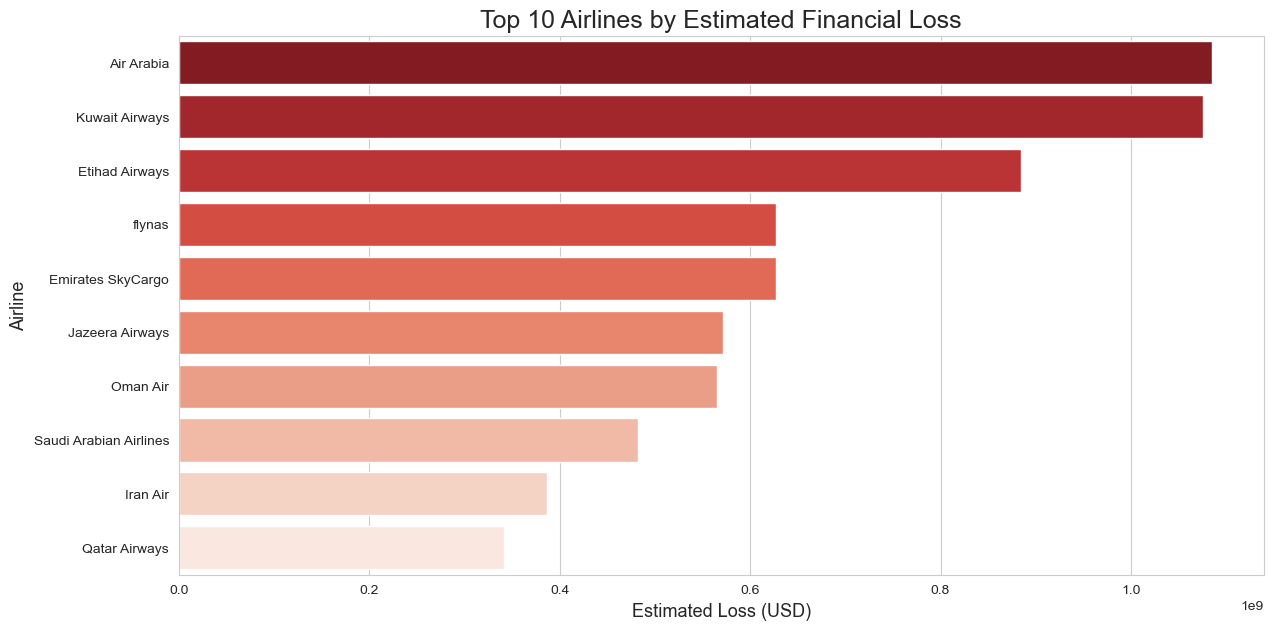

In [50]:
plt.figure(figsize=(14,7))

sns.barplot(
    data=top_airlines,
    x='estimated_loss_usd',
    y='airline',
    palette='Reds_r'
)

plt.title(
    'Top 10 Airlines by Estimated Financial Loss',
    fontsize=18
)

plt.xlabel('Estimated Loss (USD)', fontsize=13)

plt.ylabel('Airline', fontsize=13)

plt.show()

### Insight

The visualization shows that several airlines experienced extremely high financial losses due to geopolitical disruptions and airspace restrictions.

Air Arabia and Kuwait Airways recorded the highest estimated losses, both exceeding 1 billion USD.

Most heavily affected airlines are located in the Middle East region, which suggests that airlines operating near conflict zones face significantly higher operational and financial risks.

The analysis also indicates that rerouted flights and flight cancellations contribute strongly to increasing airline losses.

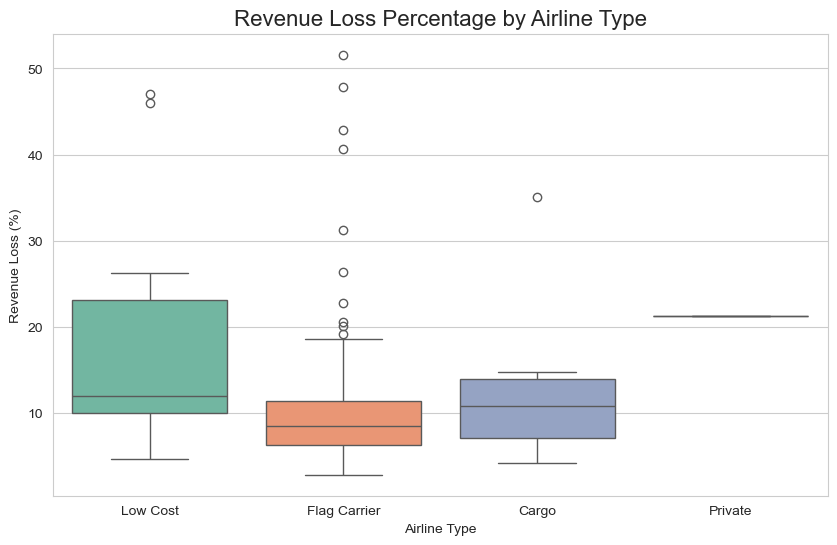

In [51]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=airline,
    x='airline_type',
    y='revenue_loss_pct',
    palette='Set2'
)

plt.title(
    'Revenue Loss Percentage by Airline Type',
    fontsize=16
)

plt.xlabel('Airline Type')

plt.ylabel('Revenue Loss (%)')

plt.show()

### Insight

The boxplot compares revenue loss percentages across different airline types.

Low Cost airlines show relatively high revenue loss percentages and greater variability, indicating that budget airlines may be more sensitive to operational disruptions.

Flag Carrier airlines generally show more stable revenue loss percentages, although several extreme outliers exist.

Cargo and Private airlines appear less represented in the dataset, but some still experienced notable financial impacts during the conflict period.

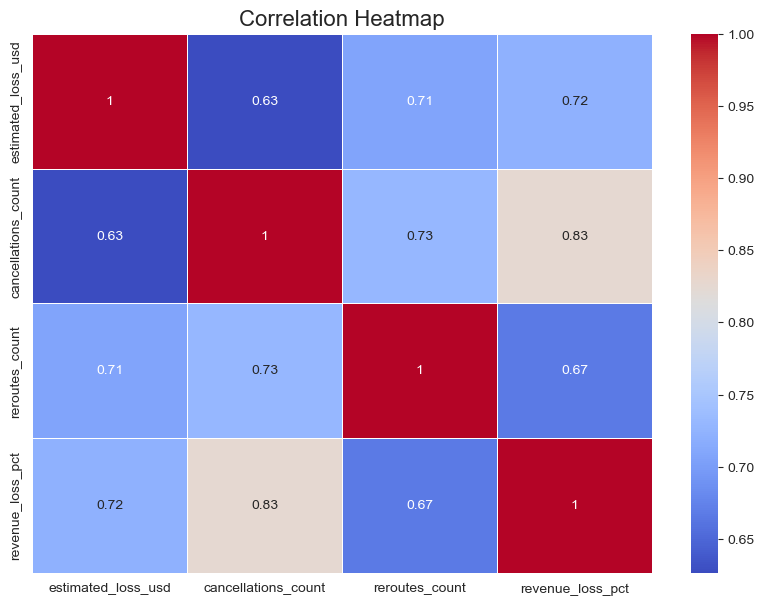

In [52]:
plt.figure(figsize=(10,7))

sns.heatmap(
    airline.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    linewidths=0.5
)

plt.title(
    'Correlation Heatmap',
    fontsize=16
)

plt.show()

### Insight

The correlation heatmap shows strong positive relationships between operational disruptions and financial losses.

Estimated airline losses are positively correlated with:
- flight cancellations
- rerouted flights
- revenue loss percentage

The strongest correlation is observed between cancellations_count and revenue_loss_pct (0.83), suggesting that increased flight cancellations significantly affect airline revenue.

Overall, the results indicate that operational disruptions are major drivers of economic damage in the aviation sector during geopolitical conflicts.

# REGION ANALYSIS

In [53]:
region_loss = airline.groupby('region')['estimated_loss_usd'].mean().sort_values(ascending=False)

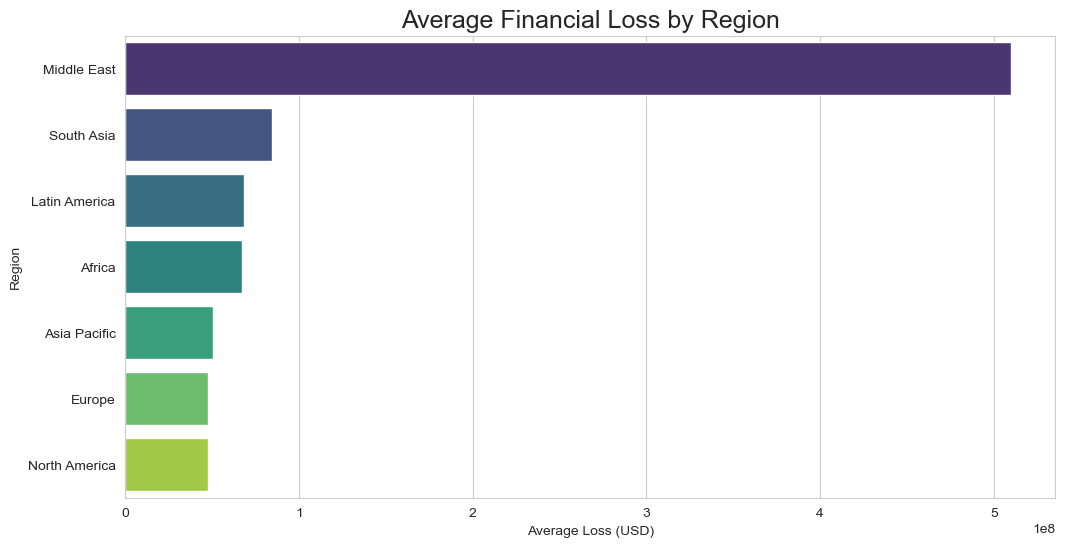

In [54]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=region_loss.values,
    y=region_loss.index,
    palette='viridis'
)

plt.title(
    'Average Financial Loss by Region',
    fontsize=18
)

plt.xlabel('Average Loss (USD)')

plt.ylabel('Region')

plt.show()

### Insight

The regional analysis shows that the Middle East experienced significantly higher average financial losses compared to all other regions.

This suggests that airlines operating close to geopolitical conflict zones are far more vulnerable to operational disruptions, airspace restrictions, and increased rerouting costs.

South Asia, Latin America, and Africa also show noticeable financial impacts, although at much lower levels than the Middle East.

Overall, the analysis highlights the strong regional concentration of aviation-related economic risk during geopolitical instability.

In [55]:
fig = px.choropleth(
    airline,
    locations='country',
    locationmode='country names',
    color='estimated_loss_usd',
    hover_name='airline',
    color_continuous_scale='Reds',
    title='Global Aviation Financial Losses'
)

fig.update_layout(
    width=1100,
    height=600
)

fig.show()

In [56]:
# Display chart
fig.show()

# Save PNG for LinkedIn
fig.write_image('aviation_map.png', scale=2)

# Save interactive HTML
fig.write_html('aviation_map.html')

### Insight

The world map visualizes the global distribution of aviation-related financial losses.

The highest financial impacts are concentrated in the Middle East region, particularly in countries located near major geopolitical tensions and airspace restrictions.

The visualization demonstrates that regional conflicts can disrupt not only local airlines but also international aviation networks connected to affected regions.

This highlights the global interconnected nature of civil aviation operations.

In [57]:
fig = px.scatter(
    airline,
    x='cancellations_count',
    y='estimated_loss_usd',
    size='reroutes_count',
    color='region',
    hover_name='airline',
    title='Operational Disruption vs Financial Loss'
)

fig.update_layout(
    width=1100,
    height=650
)

fig.show()

In [58]:
# Display chart
fig.show()

# Save PNG
fig.write_image('aviation_scatter.png', scale=2)

# Save interactive HTML
fig.write_html('aviation_scatter.html')

### Insight

The bubble chart reveals a strong relationship between operational disruptions and financial losses.

Airlines with higher numbers of flight cancellations generally experienced significantly larger financial losses.

The bubble size represents rerouted flights, indicating that airlines facing both high cancellation rates and extensive rerouting suffered the greatest operational pressure.

Several extreme outliers are visible, showing that a small number of airlines experienced exceptionally severe economic impacts compared to the rest of the industry.

In [59]:
top_airports = airport.groupby('airport_name')['flights_affected'].sum().sort_values(ascending=False).head(15)

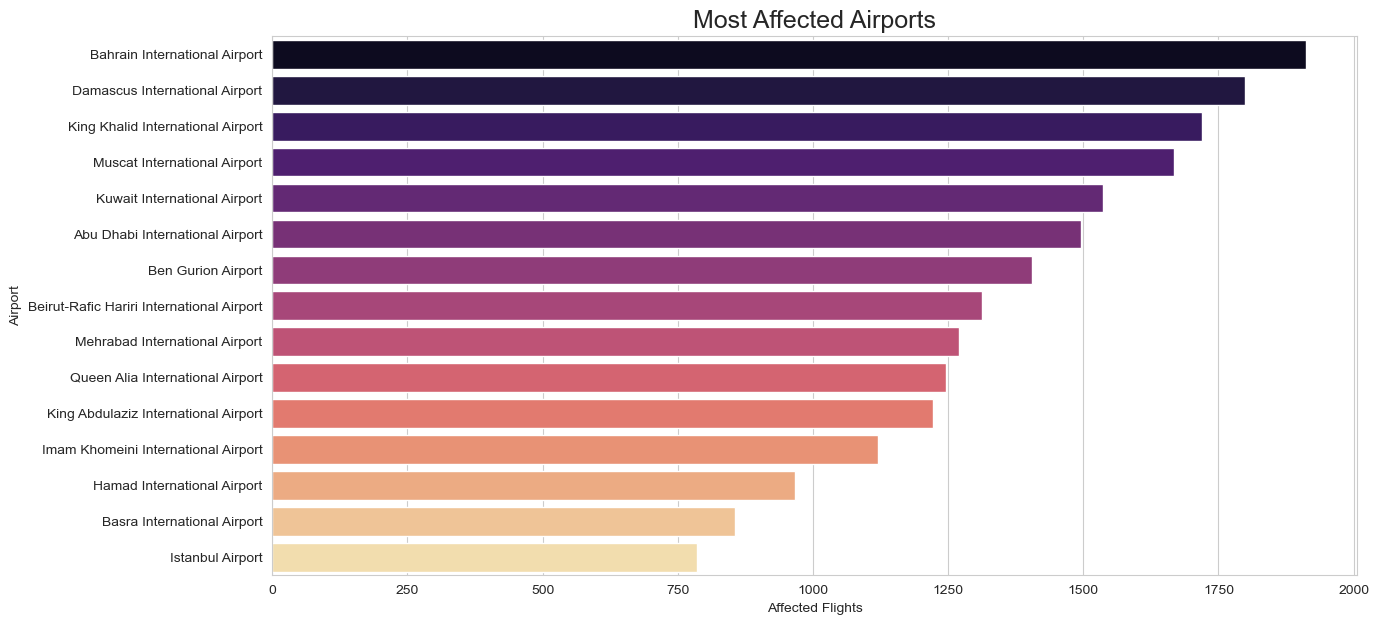

In [60]:
plt.figure(figsize=(14,7))

sns.barplot(
    x=top_airports.values,
    y=top_airports.index,
    palette='magma'
)

plt.title(
    'Most Affected Airports',
    fontsize=18
)

plt.xlabel('Affected Flights')

plt.ylabel('Airport')

plt.show()

### Insight

The analysis identifies several major Middle Eastern airports as the most operationally affected during the conflict period.

Bahrain International Airport, Damascus International Airport, and King Khalid International Airport recorded the highest numbers of affected flights.

The results suggest that airports located near geopolitical hotspots experience severe operational pressure, including flight cancellations, rerouting, and airspace restrictions.

Large international hub airports appear especially vulnerable because disruptions can quickly propagate across global aviation networks.

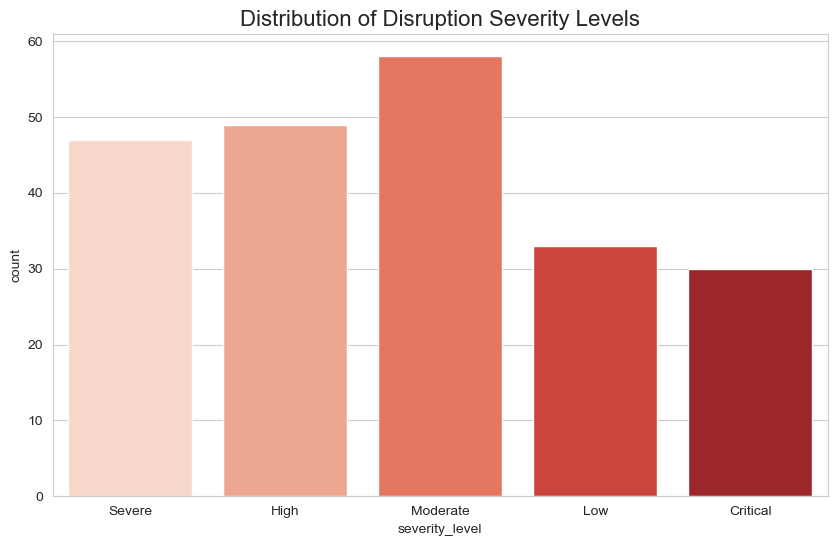

In [61]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=airport,
    x='severity_level',
    palette='Reds'
)

plt.title(
    'Distribution of Disruption Severity Levels',
    fontsize=16
)

plt.show()

### Insight

Most airport disruptions fall into the Moderate and High severity categories.

This indicates that although extreme disruptions exist, the majority of operational issues caused significant but manageable impacts on airport operations.

Critical disruptions are less frequent but still represent an important operational risk for aviation infrastructure and passenger mobility.

The distribution suggests that geopolitical conflicts create persistent medium-to-high operational stress across the aviation sector.

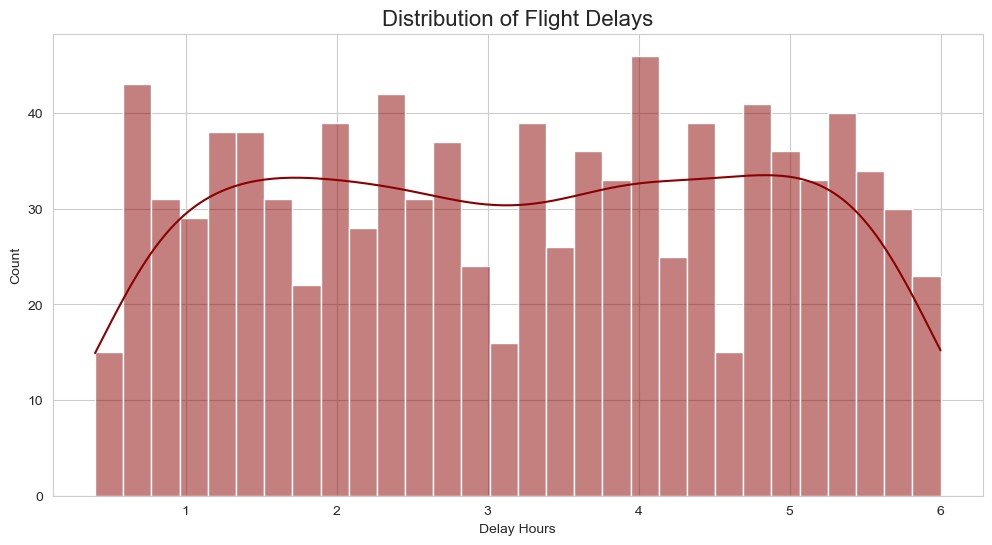

In [62]:
plt.figure(figsize=(12,6))

sns.histplot(
    reroutes['delay_hours'],
    bins=30,
    kde=True,
    color='darkred'
)

plt.title(
    'Distribution of Flight Delays',
    fontsize=16
)

plt.xlabel('Delay Hours')

plt.show()

### Insight

The delay distribution shows that most rerouted flights experienced delays between 1 and 5 hours.

The relatively wide spread of delays indicates that airspace closures and route changes create substantial operational inefficiencies for airlines.

Longer delays increase fuel consumption, crew costs, passenger dissatisfaction, and scheduling complexity.

The analysis demonstrates how geopolitical disruptions can propagate through the aviation system and affect overall network efficiency.

In [63]:
# Extra Fuel Cost Analysis
top_fuel = reroutes.sort_values(by='extra_fuel_cost_usd',ascending=False).head(15)

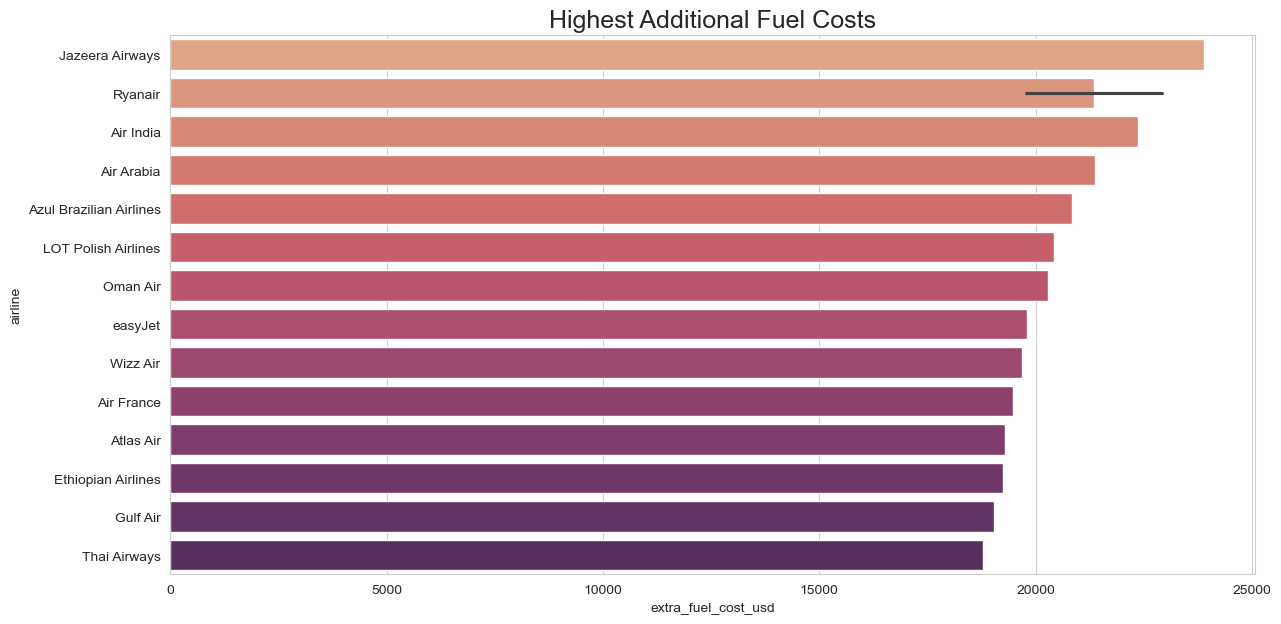

In [64]:
plt.figure(figsize=(14,7))

sns.barplot(
    data=top_fuel,
    x='extra_fuel_cost_usd',
    y='airline',
    palette='flare'
)

plt.title(
    'Highest Additional Fuel Costs',
    fontsize=18
)

plt.show()

### Insight

Several airlines experienced substantial additional fuel costs due to rerouted flight operations.

Jazeera Airways, Ryanair, and Air India recorded some of the highest extra fuel expenses.

This highlights the economic impact of forced route deviations, which increase travel distance, flight duration, and operational resource consumption.

The results demonstrate that geopolitical disruptions can generate significant indirect costs beyond flight cancellations alone.

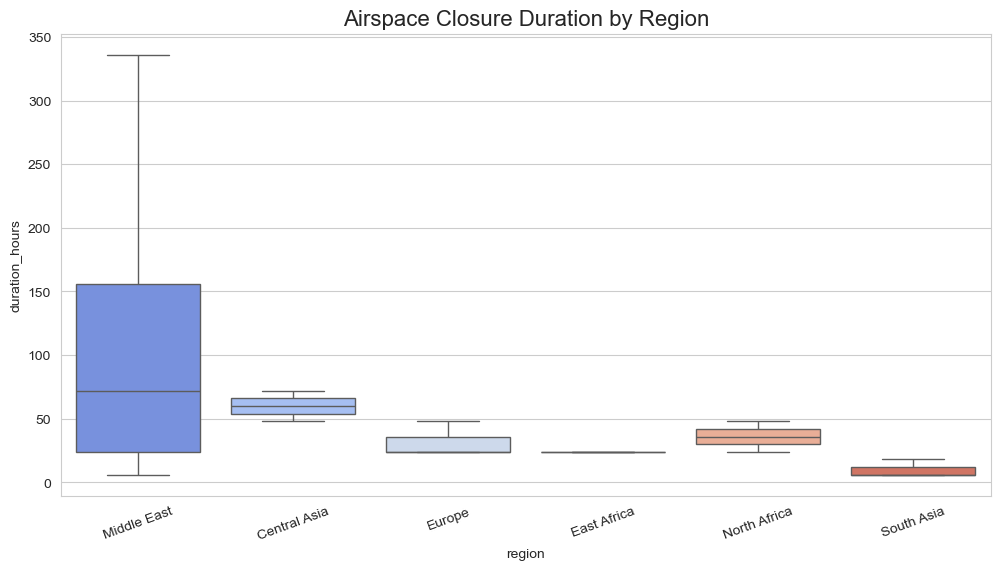

In [65]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=airspace,
    x='region',
    y='duration_hours',
    palette='coolwarm'
)

plt.xticks(rotation=20)

plt.title(
    'Airspace Closure Duration by Region',
    fontsize=16
)

plt.show()

### Insight

The Middle East region experienced the longest and most variable airspace closure durations.

Some closures lasted significantly longer than those observed in other regions, indicating prolonged operational instability and elevated geopolitical risk.

Europe and North Africa show shorter and more stable closure durations, while South Asia experienced relatively limited closure periods.

The analysis suggests that prolonged airspace restrictions are strongly concentrated near active geopolitical conflict zones.

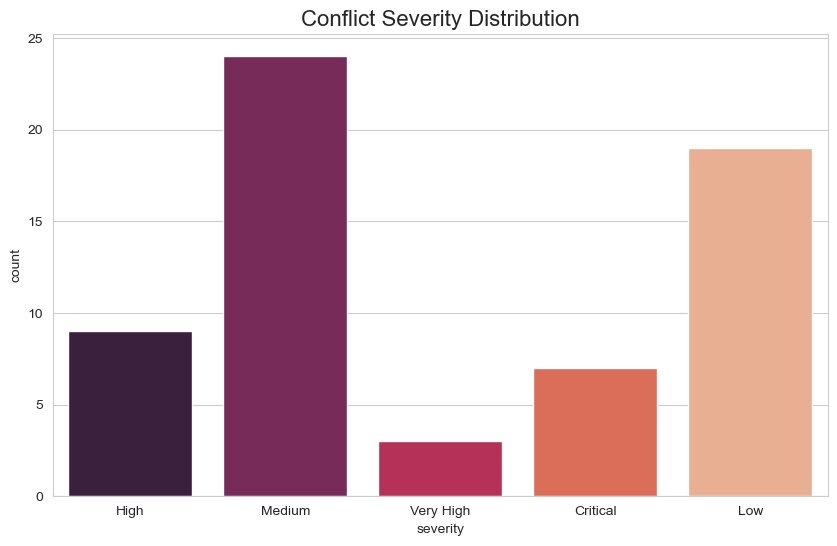

In [66]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=conflict,
    x='severity',
    palette='rocket'
)

plt.title(
    'Conflict Severity Distribution',
    fontsize=16
)

plt.show()

### Insight

Most recorded geopolitical events fall into the Medium and Low severity categories.

However, the presence of Critical and Very High severity events indicates that several incidents had the potential to cause major disruptions to aviation operations and regional stability.

The distribution suggests that even medium-level geopolitical tensions can generate widespread operational impacts on civil aviation systems.

High-severity events, although less frequent, likely contribute disproportionately to financial losses and network disruptions.

In [67]:
# Convert to Datetime
conflict['date'] = pd.to_datetime(conflict['date'])

In [68]:
cancellations['date'] = pd.to_datetime(cancellations['date'])

In [69]:
reroutes['date'] = pd.to_datetime(reroutes['date'])

In [70]:
airspace['closure_start_date'] = pd.to_datetime(airspace['closure_start_date'])
airspace['closure_end_date'] = pd.to_datetime(airspace['closure_end_date'])

In [71]:
# Conflict Events Over Time
daily_conflicts = conflict.groupby('date').size()

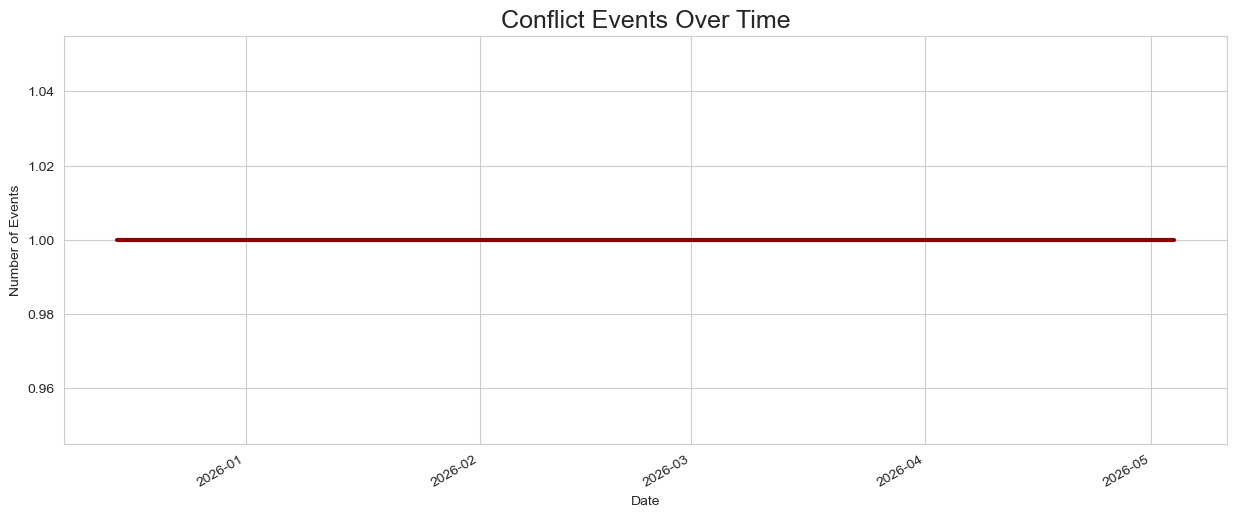

In [72]:
plt.figure(figsize=(15,6))
daily_conflicts.plot(color='darkred',linewidth=3)
plt.title('Conflict Events Over Time',fontsize=18)
plt.xlabel('Date')
plt.ylabel('Number of Events')
plt.grid(True)
plt.show()

### Insight

The conflict timeline remains relatively stable across the observed period, with approximately one major recorded conflict-related event occurring per day.

This suggests that geopolitical tensions persisted continuously throughout the analysis period rather than occurring as isolated incidents.

The consistent presence of conflict activity may have created sustained operational pressure on global aviation systems, particularly in regions located near geopolitical hotspots.

In [73]:
# Flight Cancellations Over Time
daily_cancellations = cancellations.groupby('date').size()

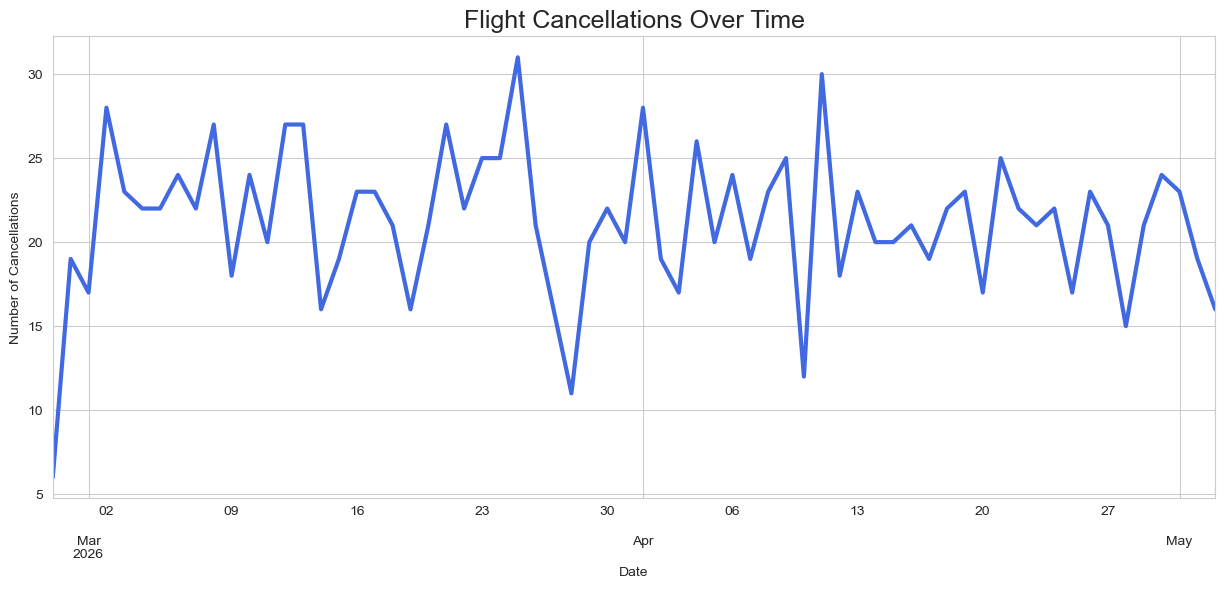

In [74]:
plt.figure(figsize=(15,6))
daily_cancellations.plot(color='royalblue',linewidth=3)
plt.title('Flight Cancellations Over Time',fontsize=18)
plt.xlabel('Date')
plt.ylabel('Number of Cancellations')
plt.grid(True)
plt.show()

### Insight

Flight cancellations fluctuated noticeably over time, with several sharp spikes reaching more than 30 cancellations per day.

These peaks likely correspond to periods of intensified geopolitical tension, temporary airspace restrictions, or operational instability.

Although cancellation levels vary daily, the overall trend indicates persistent disruption pressure on airline operations throughout the observed period.

The repeated fluctuations demonstrate how sensitive aviation systems are to geopolitical uncertainty.

In [75]:
# Average Delay Trend Over Time
daily_delay = reroutes.groupby('date')['delay_hours'].mean()

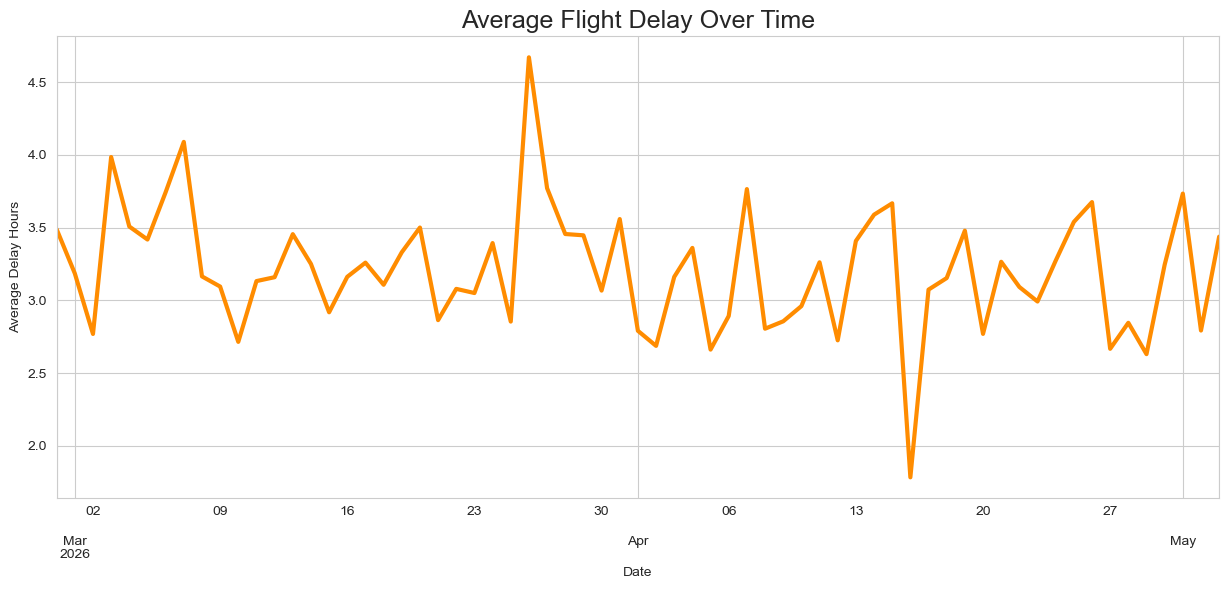

In [76]:
plt.figure(figsize=(15,6))
daily_delay.plot(color='darkorange',linewidth=3)
plt.title('Average Flight Delay Over Time',fontsize=18)
plt.xlabel('Date')
plt.ylabel('Average Delay Hours')
plt.grid(True)
plt.show()

### Insight

Average flight delays remained relatively elevated throughout the observed period, generally ranging between 2.5 and 4 hours.

Several temporary spikes indicate periods of intensified rerouting activity and operational congestion.

The large spike near the end of March suggests a short-term escalation phase where operational efficiency deteriorated significantly.

Overall, the analysis shows that geopolitical disruptions generate persistent scheduling inefficiencies and longer travel times across aviation networks.

In [77]:
# Fuel Cost Trend Over Time
daily_fuel = reroutes.groupby('date')['extra_fuel_cost_usd'].sum()

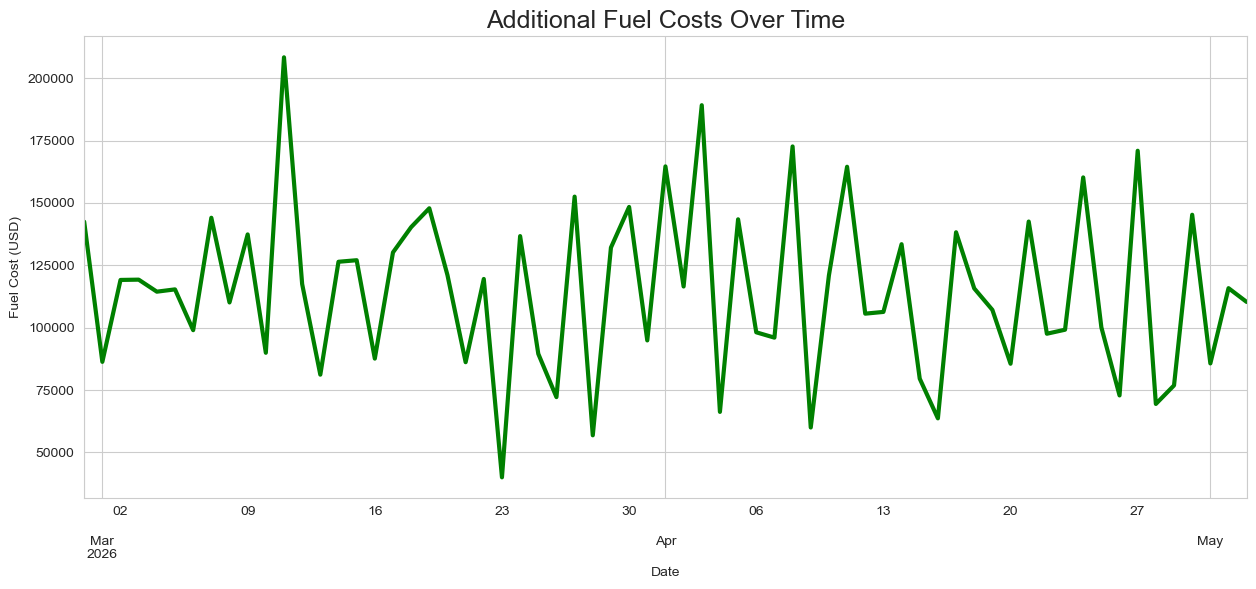

In [78]:
plt.figure(figsize=(15,6))
daily_fuel.plot(color='green',linewidth=3)
plt.title('Additional Fuel Costs Over Time',fontsize=18)
plt.xlabel('Date')
plt.ylabel('Fuel Cost (USD)')
plt.grid(True)
plt.show()

### Insight

Additional fuel costs fluctuated significantly over time, reflecting changing rerouting intensity and operational disruption levels.

Several extreme peaks exceeded 200,000 USD in additional fuel expenses, highlighting the substantial economic burden caused by longer alternative flight routes.

The volatility of fuel costs suggests that airlines faced continuously changing operational conditions during the conflict period.

These results demonstrate that geopolitical instability creates not only direct operational disruptions but also major indirect financial pressures on airlines.

In [79]:
# Flight Cancellation Rolling Mean
daily_cancellations_7d = (daily_cancellations.rolling(window=7).mean())

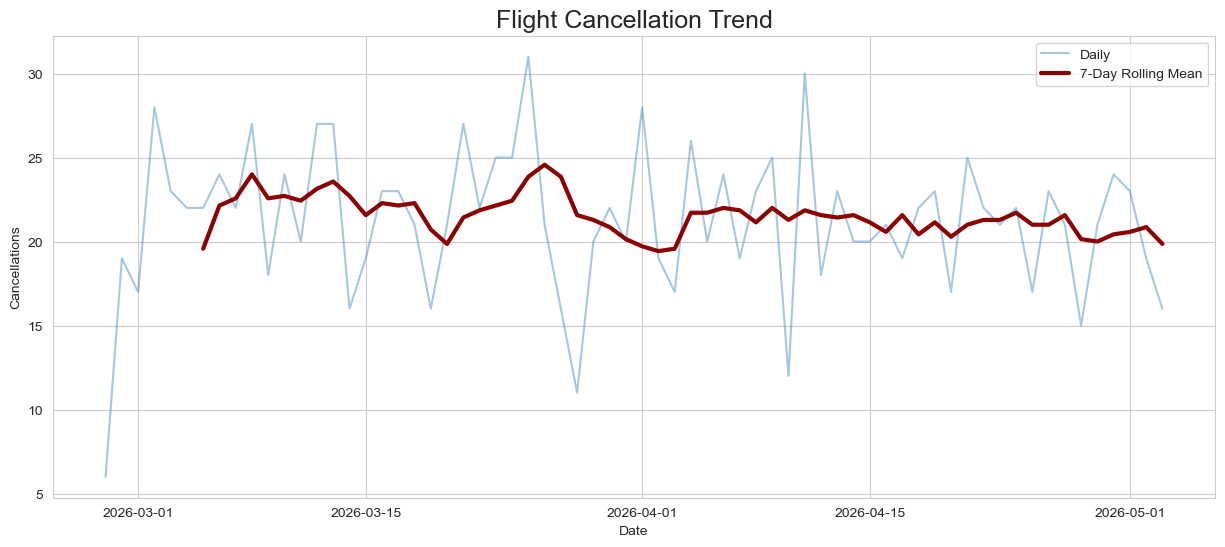

In [80]:
plt.figure(figsize=(15,6))
plt.plot(daily_cancellations.index,daily_cancellations,alpha=0.4,label='Daily')
plt.plot(daily_cancellations_7d.index,daily_cancellations_7d,linewidth=3,color='darkred',label='7-Day Rolling Mean')
plt.title('Flight Cancellation Trend',fontsize=18)
plt.xlabel('Date')
plt.ylabel('Cancellations')
plt.legend()
plt.grid(True)
plt.show()

### Insight
Die hellblaue Linie zeigt die täglichen Flugausfälle, die stark schwanken.

Die dunkelrote 7-Tage-Rolling-Mean Linie zeigt dagegen den langfristigen Trend der Flugstörungen.

Wichtige Erkenntnisse:

Die durchschnittlichen täglichen Flugausfälle bewegen sich meist zwischen 20 und 24 Flügen.
Ende März steigt die Rolling Mean deutlich an, was auf eine Eskalationsphase der Luftverkehrsstörungen hindeutet.
Ab April stabilisieren sich die Werte leicht, bleiben jedoch weiterhin auf einem erhöhten Niveau.
Das zeigt, dass geopolitische Konflikte nicht nur kurzfristige Effekte verursachen, sondern langfristige operative Auswirkungen auf die Luftfahrt haben.

In [81]:
cancellations['month'] = (cancellations['date'].dt.month_name())

In [82]:
monthly_cancel = cancellations.groupby('month').size()

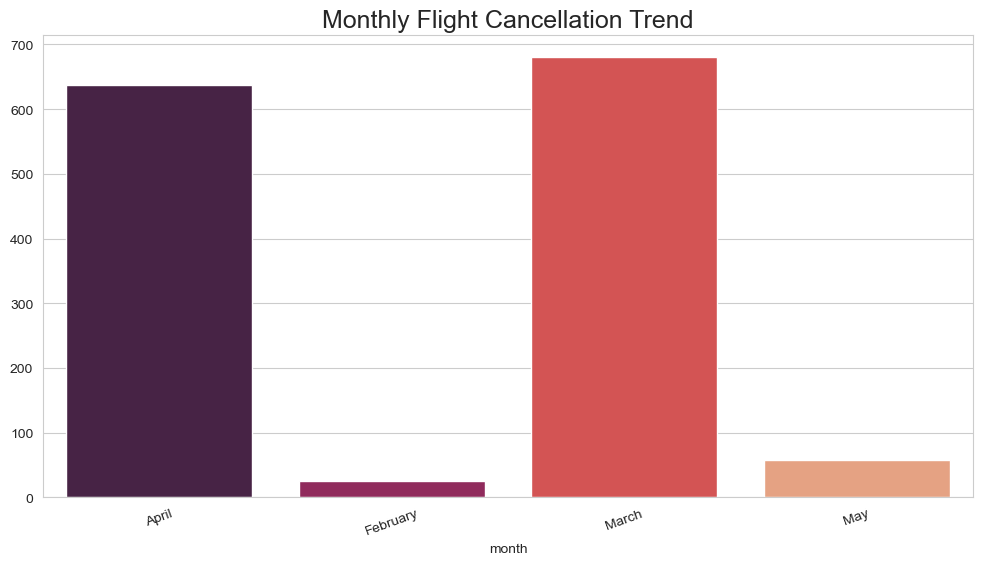

In [83]:
plt.figure(figsize=(12,6))
sns.barplot(x=monthly_cancel.index,y=monthly_cancel.values,palette='rocket')
plt.title('Monthly Flight Cancellation Trend',fontsize=18)
plt.xticks(rotation=20)
plt.show()

### Insight

Der Monatsvergleich zeigt deutliche Unterschiede bei den Flugausfällen.

Wichtige Erkenntnisse:

März und April weisen die höchsten Zahlen an Flugstornierungen auf.
Februar und Mai zeigen deutlich geringere Werte, was teilweise an weniger verfügbaren Tagen im Datensatz liegen kann.
Die Ergebnisse deuten darauf hin, dass die Hauptphase der geopolitischen Störungen besonders im März und April lag.
Dies könnte auf verstärkte Konflikte, Airspace Closures oder Sicherheitsmaßnahmen während dieses Zeitraums hinweisen.

In [84]:
# Peak Disruption Detection
peak_days = daily_cancellations.sort_values(ascending=False).head(10)

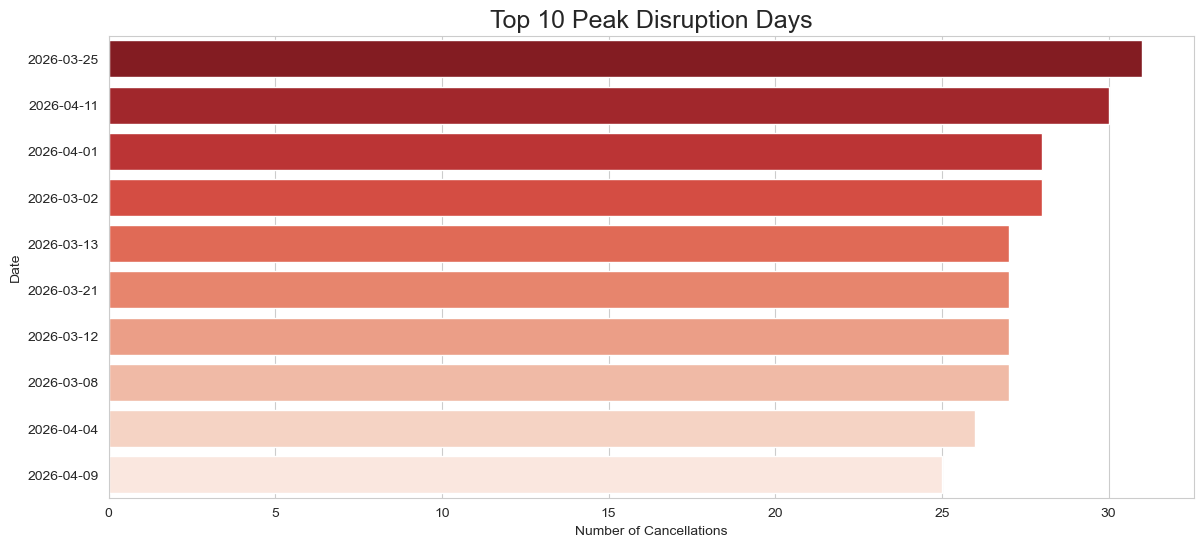

In [85]:
plt.figure(figsize=(14,6))
sns.barplot(x=peak_days.values,y=peak_days.index.astype(str),palette='Reds_r')
plt.title('Top 10 Peak Disruption Days',fontsize=18)
plt.xlabel('Number of Cancellations')
plt.ylabel('Date')
plt.show()

### Insight

Diese Analyse identifiziert die kritischsten Tage im globalen Luftverkehr.

Wichtige Erkenntnisse:

Der 25.03.2026 war der stärkste Störungstag mit über 30 Flugausfällen.
Mehrere Hochrisiko-Tage liegen im Zeitraum zwischen Ende März und Mitte April.
Dies deutet auf Phasen erhöhter geopolitischer Spannungen hin.
Solche Peak Days sind besonders relevant für:
Airlines
Flughäfen
Luftfahrtbehörden
Krisenmanagement
Risikovorhersagen

In [86]:
rolling_std = (daily_cancellations.rolling(window=7).std())

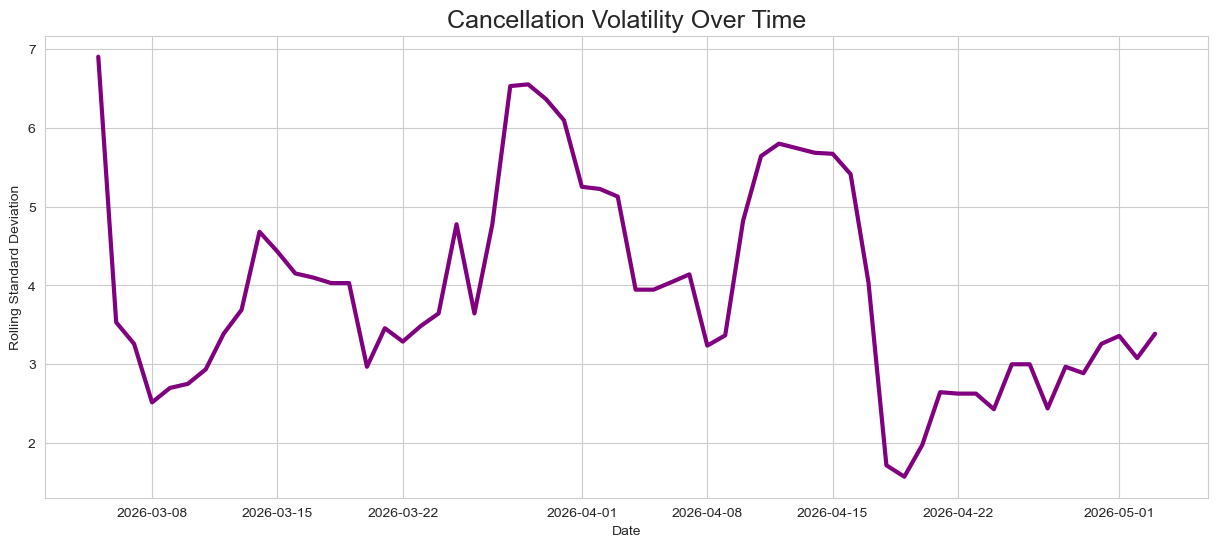

In [87]:
plt.figure(figsize=(15,6))
plt.plot(rolling_std.index,rolling_std,color='purple',linewidth=3)
plt.title('Cancellation Volatility Over Time',fontsize=18)
plt.xlabel('Date')
plt.ylabel('Rolling Standard Deviation')
plt.grid(True)
plt.show()

### Insight

Die Volatilitätsanalyse misst die Instabilität der täglichen Flugausfälle.

Wichtige Erkenntnisse:

Ende März und Mitte April steigt die Volatilität stark an.
Hohe Volatilität bedeutet:
unvorhersehbare Luftverkehrslage
operative Unsicherheit
schwierige Flugplanung
Nach dem 18. April sinkt die Volatilität deutlich.
Das deutet auf eine temporäre Stabilisierung der Luftverkehrssituation hin.
Gegen Anfang Mai steigt die Volatilität leicht erneut an.

In [88]:
# Escalation Phase Detection
conflict_counts = conflict.groupby('date').size().reset_index(name='events')

In [89]:
threshold = conflict_counts['events'].mean() + (2 * conflict_counts['events'].std())

In [90]:
escalation_days = conflict_counts[conflict_counts['events'] > threshold]

In [91]:
escalation_days

,date,events


The current dataset does not contain major multi-event escalation peaks per day.
However, the escalation detection framework demonstrates how anomaly detection techniques can be applied in larger real-world geopolitical monitoring systems.

# Feature Engineering

In [92]:
# Airline Risk Score

airline['airline_risk_score'] = (
    airline['estimated_loss_usd'] * 0.4 +
    airline['cancellations_count'] * 0.3 +
    airline['reroutes_count'] * 0.3
)

In [93]:
# Fuel Efficiency Impact
reroutes['fuel_cost_per_km'] = (
    reroutes['extra_fuel_cost_usd'] /
    reroutes['additional_distance_km']
)

In [94]:
# Delay Severity Score
reroutes['delay_severity_score'] = (
    reroutes['delay_hours'] *
    reroutes['additional_distance_km']
)

In [95]:
# Airport Operational Risk
airport['operational_risk_score'] = (
    airport['flights_affected'] *
    airport['duration_hours']
)

In [96]:
# Closure Intensity
airspace['closure_intensity'] = (
    airspace['duration_hours'] *
    airspace['flights_affected']
)

# Modelling

In [97]:
x = airline[['cancellations_count','reroutes_count','revenue_loss_pct']]

In [98]:
y = airline['estimated_loss_usd']

In [99]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.20, random_state=42)

In [100]:
lr = LinearRegression()

In [101]:
lr.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [102]:
y_pred = lr.predict(x_test)

In [103]:
print('R2 Score:', r2_score(y_test, y_pred))
print('MAE:', mean_absolute_error(y_test, y_pred))
print('RMSE:', mean_squared_error(y_test, y_pred) ** 0.5)

R2 Score: 0.44671723022944787
MAE: 141774399.89474338
RMSE: 223362704.71889105


### Random Forest

In [104]:
rf=RandomForestRegressor(n_estimators=200,max_depth=5,random_state=42)

In [105]:
rf.fit(x_train, y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [106]:
rf_pred = rf.predict(x_test)

In [107]:
print('R2 Score:', r2_score(y_test, rf_pred))
print('MAE:', mean_absolute_error(y_test, rf_pred))
print('RMSE:', mean_squared_error(y_test, rf_pred) ** 0.5)

R2 Score: 0.7226470920758417
MAE: 85785755.27086258
RMSE: 158144265.62567335


### Feature Importance

In [108]:
importance = pd.DataFrame({'Feature': x.columns,'Importance': rf.feature_importances_})
importance = importance.sort_values(by='Importance',ascending=False)

In [109]:
importance

,Feature,Importance
2,revenue_loss_pct,0.492741
1,reroutes_count,0.352864
0,cancellations_count,0.154395


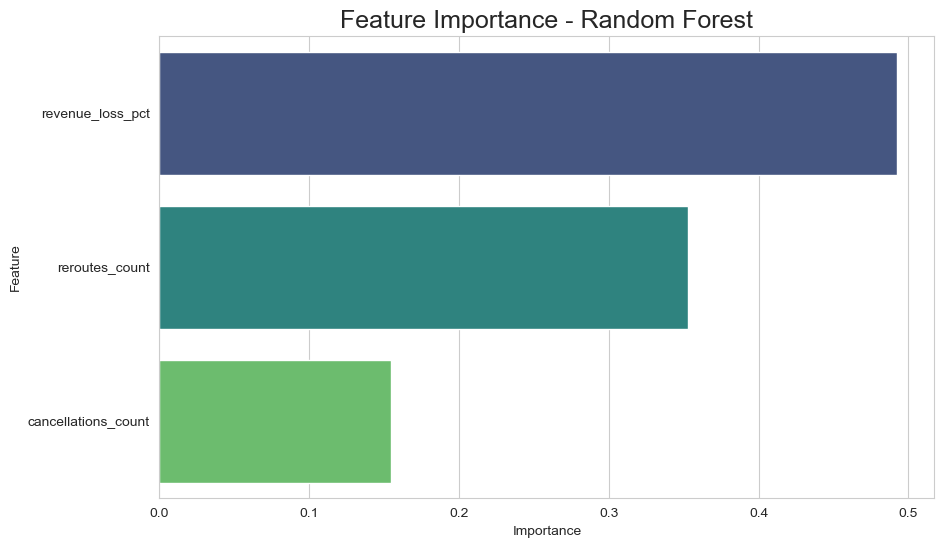

In [110]:
plt.figure(figsize=(10,6))
sns.barplot(data=importance,x='Importance',y='Feature',palette='viridis')
plt.title('Feature Importance - Random Forest',fontsize=18)
plt.show()

### XGBRegressor

In [111]:
xgb=XGBRegressor(n_estimators=300,learning_rate=0.05,max_depth=4,random_state=42)

In [112]:
xgb.fit(x_train, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [113]:
xgb_pred = xgb.predict(x_test)

In [114]:
print('R2 Score:', r2_score(y_test, xgb_pred))
print('MAE:', mean_absolute_error(y_test, xgb_pred))
print('RMSE:', mean_squared_error(y_test, xgb_pred) ** 0.5)

R2 Score: 0.6404567487538282
MAE: 106755144.14285715
RMSE: 180058097.7580086


### Feature Importance

In [115]:
importance_xgb = pd.DataFrame({'Feature': x.columns,'Importance': xgb.feature_importances_})
importance_xgb = importance_xgb.sort_values(by='Importance',ascending=False)

In [116]:
importance_xgb

,Feature,Importance
1,reroutes_count,0.483820
2,revenue_loss_pct,0.386123
0,cancellations_count,0.130057


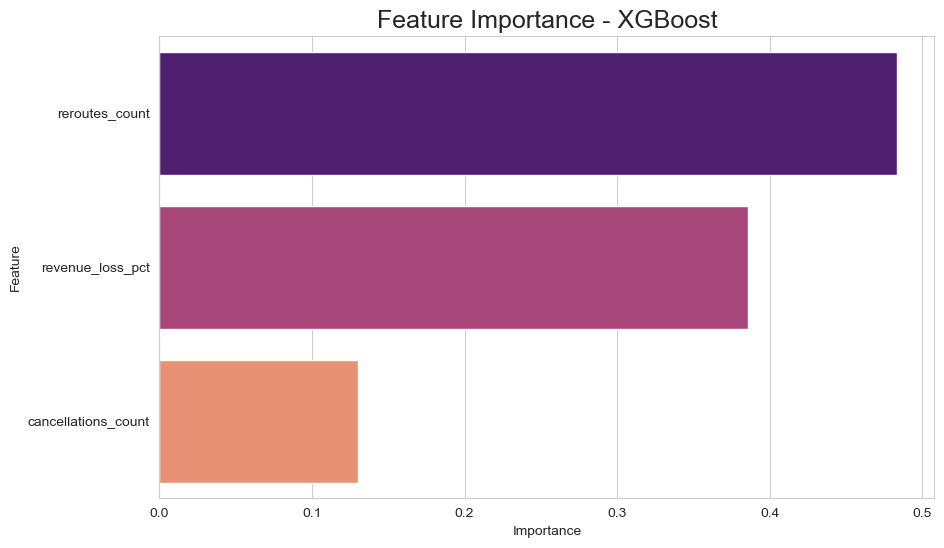

In [117]:
plt.figure(figsize=(10,6))
sns.barplot(data=importance_xgb,x='Importance',y='Feature',palette='magma')
plt.title('Feature Importance - XGBoost',fontsize=18)
plt.show()

In [118]:
explainer = shap.TreeExplainer(rf)

In [119]:
shap_values = explainer.shap_values(x_test)

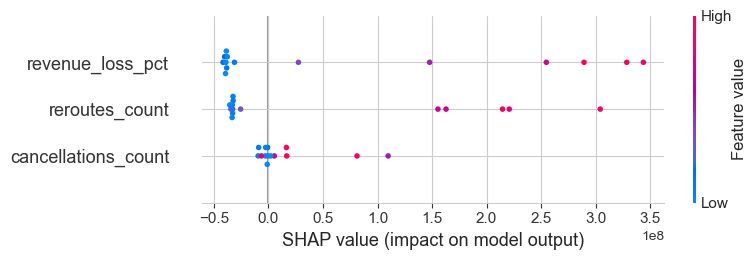

In [120]:
shap.summary_plot(shap_values,x_test)

#  Conclusion

This project explored how aviation disruptions and estimated financial losses vary across airlines, airports, regions, and time in the supplied datasets. The exploratory analysis shows particularly large estimated losses among Middle Eastern airlines, alongside relationships between cancellations, rerouting activity, and financial impact. Time-series visualizations also reveal fluctuations in cancellations, delays, and additional fuel costs.

Three regression models were evaluated on an 80/20 train–test split. Random Forest performed best on the saved test results, with an R² of 0.723, MAE of approximately $85.8 million, and RMSE of approximately $158.1 million. XGBoost achieved an R² of 0.640, while Linear Regression achieved 0.447. These results demonstrate useful predictive patterns within this dataset, but do not establish causal effects or performance on future disruptions.

Limitations and next steps:
- Document and validate the datasets' provenance, coverage, and whether figures are observed or simulated.
- Test model robustness with cross-validation and, where dates are relevant, time-based validation.
- Review possible target leakage: revenue_loss_pct may be closely related to the financial-loss target and might not be known at prediction time.
- Improve feature engineering, assess uncertainty, and compare results against a simple baseline.

Overall, the project demonstrates an end-to-end data science workflow—from exploratory analysis and interactive visualization to regression modeling and interpretation—while highlighting the importance of transparent data assumptions and careful validation.